In [20]:
import warnings
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "CROPS"

print("Libraries imported successfully.")


Libraries imported successfully.


In [21]:
import pandas as pd

# Load the crop recommendation dataset
df = pd.read_csv("Crop recommendation dataset.csv")

# Input features (X)
features = [
    "SOIL",
    "SEASON",
    "SOWN",
    "WATER_SOURCE",
    "SOIL_PH",
    "TEMP",
    "RELATIVE_HUMIDITY",
    "N",
    "P",
    "K"
]

X = df[features].copy()

# Target variable (y)
y = df["CROPS"].copy()

print("Dataset shape:", df.shape)
print("Input features:", X.shape)
print("Target labels:", y.shape)
print("Number of crop classes:", y.nunique())

Dataset shape: (57000, 23)
Input features: (57000, 10)
Target labels: (57000,)
Number of crop classes: 57


In [22]:
print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)
print("\nDataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())
print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types and Non-Null Counts:")
df.info()
print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nExact Duplicate Rows:", df.duplicated().sum())
if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found. Available columns: {df.columns.tolist()}")


DATASET INFORMATION

Dataset Shape: (57000, 23)

First 5 Rows:


,CROPS,TYPE_OF_CROP,SOIL,SEASON,SOWN,HARVESTED,WATER_SOURCE,SOIL_PH,SOIL_PH_HIGH,CROPDURATION,...,WATERREQUIRED,WATERREQUIRED_MAX,RELATIVE_HUMIDITY,RELATIVE_HUMIDITY_MAX,N,N_MAX,P,P_MAX,K,K_MAX
0,rice,cereals,Alluvial soil,kharif,Jun,Sep,irrigated,7.6,8.0,116.9,...,2462.3,2500,73.8,80,82.4,100,40.7,60,42.2,60
1,rice,cereals,Loamy soil,kharif,Jul,Oct,rainfed,6.2,8.0,117.9,...,1237.5,2500,60.9,80,90.5,100,51.3,60,46.2,60
2,rice,cereals,Clay soil,kharif,Jun,Sep,irrigated,6.7,8.0,117.7,...,1075.1,2500,67.5,80,86.2,100,50.7,60,44.4,60
3,rice,cereals,Alluvial soil,kharif,Jul,Oct,rainfed,6.1,8.0,149.8,...,1549.9,2500,73.6,80,91.3,100,51.3,60,44.5,60
4,rice,cereals,Loamy soil,kharif,Jun,Sep,irrigated,8.0,8.0,131.7,...,1306.4,2500,60.3,80,81.3,100,48.6,60,51.0,60



Column Names:
['CROPS', 'TYPE_OF_CROP', 'SOIL', 'SEASON', 'SOWN', 'HARVESTED', 'WATER_SOURCE', 'SOIL_PH', 'SOIL_PH_HIGH', 'CROPDURATION', 'CROPDURATION_MAX', 'TEMP', 'MAX_TEMP', 'WATERREQUIRED', 'WATERREQUIRED_MAX', 'RELATIVE_HUMIDITY', 'RELATIVE_HUMIDITY_MAX', 'N', 'N_MAX', 'P', 'P_MAX', 'K', 'K_MAX']

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57000 entries, 0 to 56999
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CROPS                  57000 non-null  object 
 1   TYPE_OF_CROP           57000 non-null  object 
 2   SOIL                   57000 non-null  object 
 3   SEASON                 57000 non-null  object 
 4   SOWN                   57000 non-null  object 
 5   HARVESTED              57000 non-null  object 
 6   WATER_SOURCE           57000 non-null  object 
 7   SOIL_PH                57000 non-null  float64
 8   SOIL_PH_HIGH           57000

,Missing values
CROPS,0
TYPE_OF_CROP,0
SOIL,0
SEASON,0
SOWN,0
HARVESTED,0
WATER_SOURCE,0
SOIL_PH,0
SOIL_PH_HIGH,0
CROPDURATION,0



Exact Duplicate Rows: 0


In [23]:
print("=" * 70)
print("DESCRIPTIVE STATISTICS")
print("=" * 70)
display(df.describe(include="all").T)


DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CROPS,57000,57,rice,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TYPE_OF_CROP,57000,10,vegetables,22000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SOIL,57000,34,sandy Loamy soil,15332,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEASON,57000,3,Zaid,23000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SOWN,57000,8,Jun,14100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HARVESTED,57000,7,Apr,9610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WATER_SOURCE,57000,2,irrigated,31500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SOIL_PH,57000.0,NaN,NaN,NaN,6.624367,0.649972,5.0,6.2,6.6,7.0,9.0
SOIL_PH_HIGH,57000.0,NaN,NaN,NaN,7.245614,0.60931,6.0,6.8,7.0,7.5,9.0
CROPDURATION,57000.0,NaN,NaN,NaN,109.347488,52.931444,21.0,75.9,99.9,120.5,330.0


TARGET DISTRIBUTION


,Samples per crop
CROPS,
rice,1000
wheat,1000
maize,1000
sorghum,1000
Pearl millet,1000
ragi,1000
panivaragu,1000
samai,1000
thinai,1000


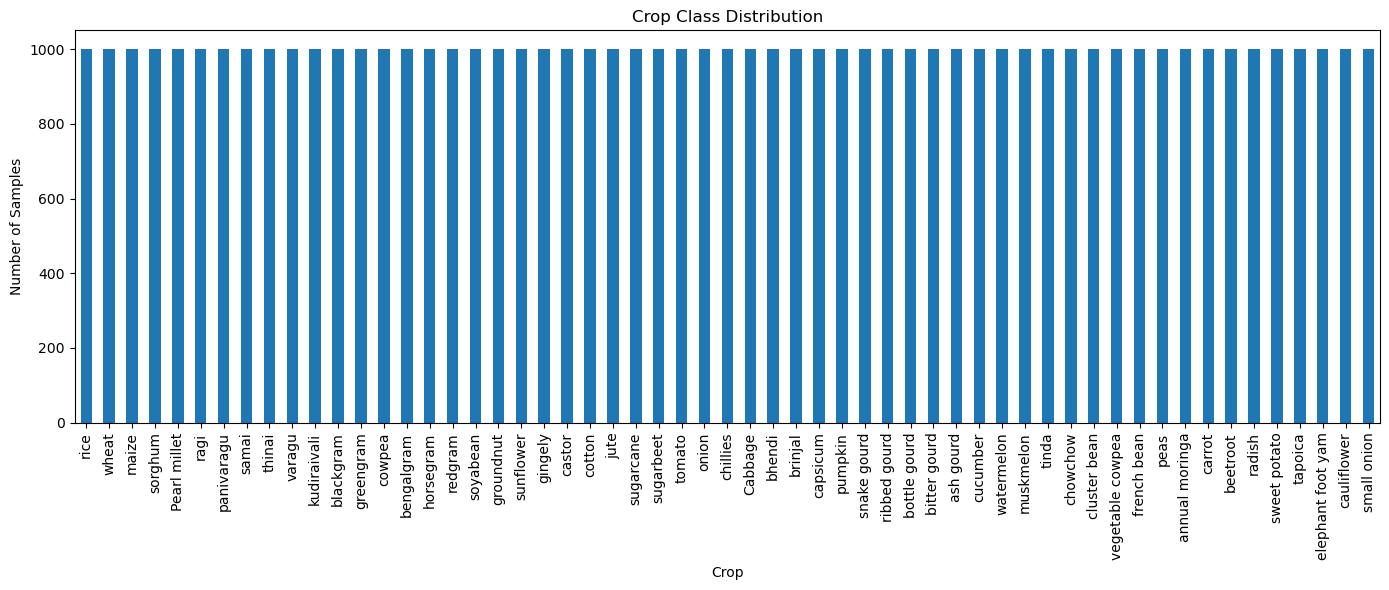

In [24]:
print("=" * 70)
print("TARGET DISTRIBUTION")
print("=" * 70)
display(df[TARGET].value_counts().to_frame("Samples per crop"))
plt.figure(figsize=(14, 6))
df[TARGET].value_counts().plot(kind="bar")
plt.title("Crop Class Distribution")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [25]:
# Conservative feature set: features intended to be available before recommending a crop.
# Exclude fields that may reveal the answer or may be derived from crop identity:
# TYPE_OF_CROP, HARVESTED, CROPDURATION*, WATERREQUIRED*, *_MAX and MAX_TEMP.
candidate_features = [
    "SOIL", "SEASON", "SOWN", "WATER_SOURCE",
    "SOIL_PH", "TEMP", "RELATIVE_HUMIDITY", "N", "P", "K"
]
missing = [col for col in candidate_features if col not in df.columns]
if missing:
    raise ValueError(
        f"Expected feature columns not found: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df = df.dropna(subset=[TARGET]).copy()
X = df[candidate_features].copy()
y_original = df[TARGET].astype(str).copy()

print("Features matrix shape:", X.shape)
print("Target vector shape:", y_original.shape)
print("Features used:", candidate_features)


Features matrix shape: (57000, 10)
Target vector shape: (57000,)
Features used: ['SOIL', 'SEASON', 'SOWN', 'WATER_SOURCE', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K']


In [26]:
print("=" * 70)
print("FEATURE INFORMATION")
print("=" * 70)
print("Feature names:", X.columns.tolist())
print("Number of features:", X.shape[1])
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [col for col in X.columns if col not in categorical_features]
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)


FEATURE INFORMATION
Feature names: ['SOIL', 'SEASON', 'SOWN', 'WATER_SOURCE', 'SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K']
Number of features: 10
Categorical features: ['SOIL', 'SEASON', 'SOWN', 'WATER_SOURCE']
Numeric features: ['SOIL_PH', 'TEMP', 'RELATIVE_HUMIDITY', 'N', 'P', 'K']


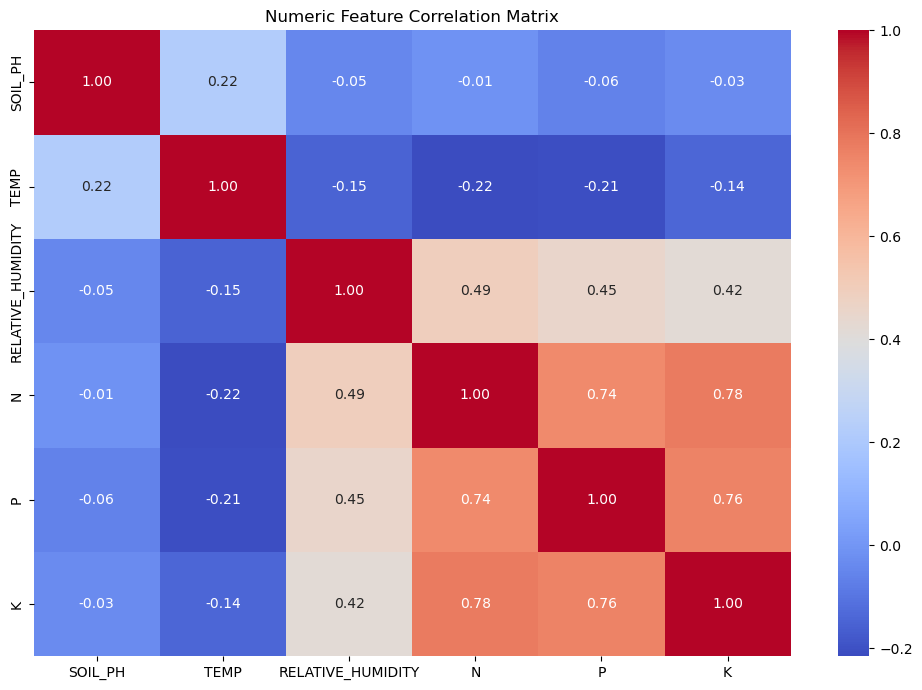

In [27]:
# Correlation matrix for numeric columns only
numeric_X = X.select_dtypes(include=np.number)
if numeric_X.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_X.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Numeric Feature Correlation Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")


In [28]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

print("=" * 70)
print("STRATIFIED DATA SPLIT")
print("=" * 70)
print(f"Training samples   : {len(X_train):,} ({len(X_train)/len(X):.1%})")
print(f"Validation samples : {len(X_val):,} ({len(X_val)/len(X):.1%})")
print(f"Testing samples    : {len(X_test):,} ({len(X_test)/len(X):.1%})")


STRATIFIED DATA SPLIT
Training samples   : 39,900 (70.0%)
Validation samples : 8,550 (15.0%)
Testing samples    : 8,550 (15.0%)


In [29]:
# Preprocessing is fitted inside each pipeline on training data only.
def make_preprocessor(X_fit):
    categorical = X_fit.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric = [col for col in X_fit.columns if col not in categorical]

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    return ColumnTransformer([
        ("categorical", categorical_pipe, categorical),
        ("numeric", numeric_pipe, numeric)
    ])

# All models receive the same feature inputs and preprocessing approach.
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE, max_iter=10000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    "Gaussian Naive Bayes": GaussianNB(),
    "SGD Classifier": SGDClassifier(loss="modified_huber", max_iter=1500, random_state=RANDOM_STATE),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(64,), max_iter=100, early_stopping=True, random_state=RANDOM_STATE)
}

try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        objective="multi:softprob", eval_metric="mlogloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1
    )
except ImportError:
    print("XGBoost not installed. To include it, run: %pip install xgboost")

print(f"Configured {len(models)} ML models.")


Configured 12 ML models.


In [30]:
validation_results = []
fitted_models = {}

print("=" * 70)
print("MODEL TRAINING & VALIDATION")
print("=" * 70)

for name, estimator in models.items():
    print("Training:", name)
    model = Pipeline([
        ("preprocessor", make_preprocessor(X_train)),
        ("model", clone(estimator))
    ])
    try:
        model.fit(X_train, y_train)
        fitted_models[name] = model
        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)

        validation_results.append({
            "Model": name,
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Validation Accuracy": accuracy_score(y_val, val_pred),
            "Validation Precision (Macro)": precision_score(y_val, val_pred, average="macro", zero_division=0),
            "Validation Recall (Macro)": recall_score(y_val, val_pred, average="macro", zero_division=0),
            "Validation F1 (Macro)": f1_score(y_val, val_pred, average="macro", zero_division=0)
        })
        print(f"  train={validation_results[-1]['Train Accuracy']:.2%}, "
              f"validation={validation_results[-1]['Validation Accuracy']:.2%}")
    except Exception as e:
        print(f"  Model failed: {type(e).__name__}: {e}")

if not validation_results:
    raise RuntimeError("Every model failed. Review the error messages above.")


MODEL TRAINING & VALIDATION
Training: Logistic Regression
  train=96.37%, validation=96.29%
Training: KNN
  train=96.83%, validation=94.99%
Training: Linear SVM
  train=94.71%, validation=94.57%
Training: Decision Tree
  train=100.00%, validation=97.53%
Training: Random Forest
  train=100.00%, validation=98.44%
Training: Gradient Boosting
  train=99.44%, validation=98.37%
Training: AdaBoost
  train=5.26%, validation=5.26%
Training: Extra Trees
  train=100.00%, validation=97.57%
Training: Gaussian Naive Bayes
  Model failed: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
Training: SGD Classifier
  train=92.93%, validation=92.71%
Training: MLP Neural Network
  Model failed: TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
Training: XGBoost
  Model failed: ValueError: Invalid classes inferred from uniq

In [31]:
validation_df = pd.DataFrame(validation_results).sort_values(
    by="Validation Accuracy", ascending=False
).reset_index(drop=True)
print("VALIDATION RESULTS")
display(validation_df.style.format({
    col: "{:.2%}" for col in validation_df.columns if col != "Model"
}))


VALIDATION RESULTS


,Model,Train Accuracy,Validation Accuracy,Validation Precision (Macro),Validation Recall (Macro),Validation F1 (Macro)
0,Random Forest,100.00%,98.44%,98.49%,98.44%,98.44%
1,Gradient Boosting,99.44%,98.37%,98.44%,98.37%,98.37%
2,Extra Trees,100.00%,97.57%,97.65%,97.57%,97.56%
3,Decision Tree,100.00%,97.53%,97.54%,97.53%,97.53%
4,Logistic Regression,96.37%,96.29%,96.31%,96.29%,96.27%
5,KNN,96.83%,94.99%,95.09%,94.99%,94.95%
6,Linear SVM,94.71%,94.57%,94.67%,94.57%,94.49%
7,SGD Classifier,92.93%,92.71%,93.89%,92.71%,92.60%
8,AdaBoost,5.26%,5.26%,1.49%,5.26%,1.96%


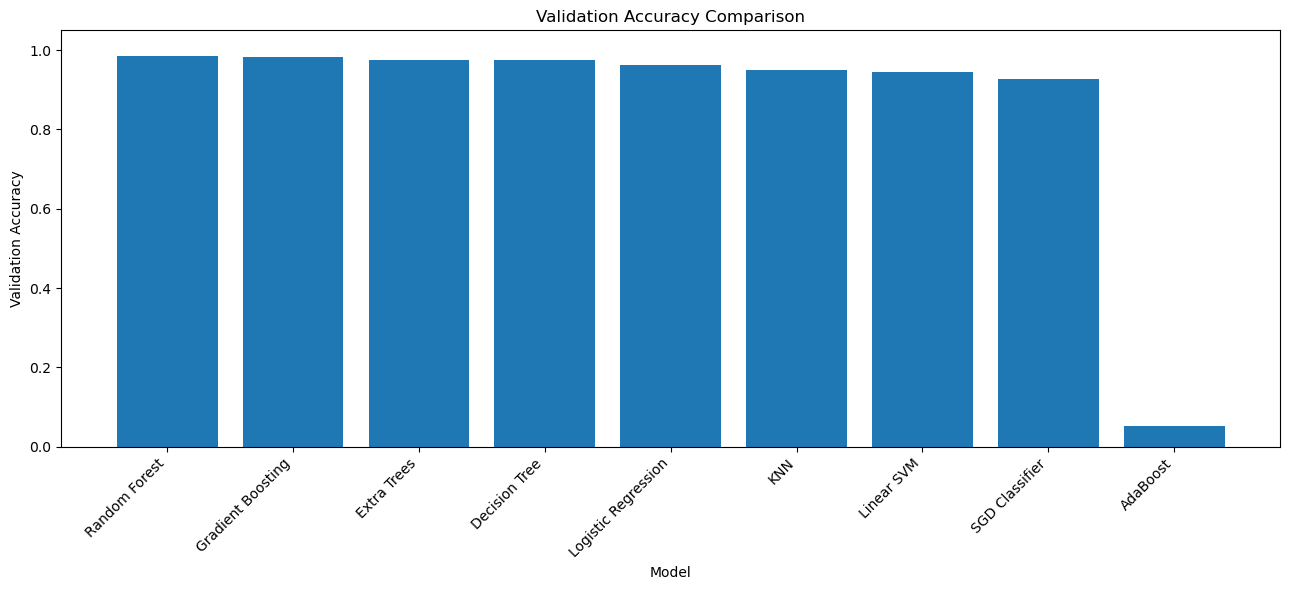

In [32]:
plt.figure(figsize=(13, 6))
plt.bar(validation_df["Model"], validation_df["Validation Accuracy"])
plt.title("Validation Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [33]:
best_model_name = validation_df.iloc[0]["Model"]
best_validation_accuracy = validation_df.iloc[0]["Validation Accuracy"]
print("=" * 70)
print("BEST MODEL SELECTED USING VALIDATION DATA")
print("=" * 70)
print("Best model:", best_model_name)
print(f"Validation accuracy: {best_validation_accuracy:.2%}")


BEST MODEL SELECTED USING VALIDATION DATA
Best model: Random Forest
Validation accuracy: 98.44%


In [34]:
# Combine training and validation data for final fitting.
# The test set remains separate and is not used for model selection.
X_development = pd.concat([X_train, X_val], axis=0)
y_development = np.concatenate([y_train, y_val])
print(f"Development samples (train + validation): {len(X_development):,}")


Development samples (train + validation): 48,450


In [35]:
final_model = Pipeline([
    ("preprocessor", make_preprocessor(X_development)),
    ("model", clone(models[best_model_name]))
])
print("Final model architecture:")
print(final_model)


Final model architecture:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['SOIL', 'SEASON', 'SOWN',
                                                   'WATER_SOURCE']),
                                                 ('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                      

In [36]:
print("Training the selected model on train + validation data...")
final_model.fit(X_development, y_development)
print("Final training complete.")


Training the selected model on train + validation data...
Final training complete.


In [37]:
final_prediction = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, final_prediction)
test_precision = precision_score(y_test, final_prediction, average="macro", zero_division=0)
test_recall = recall_score(y_test, final_prediction, average="macro", zero_division=0)
test_f1 = f1_score(y_test, final_prediction, average="macro", zero_division=0)


In [38]:
print("=" * 70)
print("FINAL HELD-OUT TEST RESULT")
print("=" * 70)
print("Selected Model :", best_model_name)
print(f"Test Accuracy  : {test_accuracy:.2%}")
print(f"Test Precision : {test_precision:.2%}")
print(f"Test Recall    : {test_recall:.2%}")
print(f"Test Macro-F1  : {test_f1:.2%}")


FINAL HELD-OUT TEST RESULT
Selected Model : Random Forest
Test Accuracy  : 98.68%
Test Precision : 98.72%
Test Recall    : 98.68%
Test Macro-F1  : 98.68%


In [40]:
from sklearn.metrics import classification_report
import numpy as np

print("CLASSIFICATION REPORT - TEST SET")

print(classification_report(
    y_test,
    final_prediction,
    zero_division=0
))

CLASSIFICATION REPORT - TEST SET
                   precision    recall  f1-score   support

          Cabbage       1.00      1.00      1.00       150
     Pearl millet       1.00      1.00      1.00       150
   annual moringa       1.00      0.95      0.98       150
        ash gourd       1.00      1.00      1.00       150
         beetroot       1.00      1.00      1.00       150
       bengalgram       1.00      1.00      1.00       150
           bhendi       1.00      1.00      1.00       150
     bitter gourd       1.00      1.00      1.00       150
        blackgram       1.00      1.00      1.00       150
     bottle gourd       0.97      0.95      0.96       150
          brinjal       1.00      1.00      1.00       150
         capsicum       1.00      1.00      1.00       150
           carrot       1.00      1.00      1.00       150
           castor       0.85      0.79      0.82       150
      cauliflower       1.00      1.00      1.00       150
         chillies     

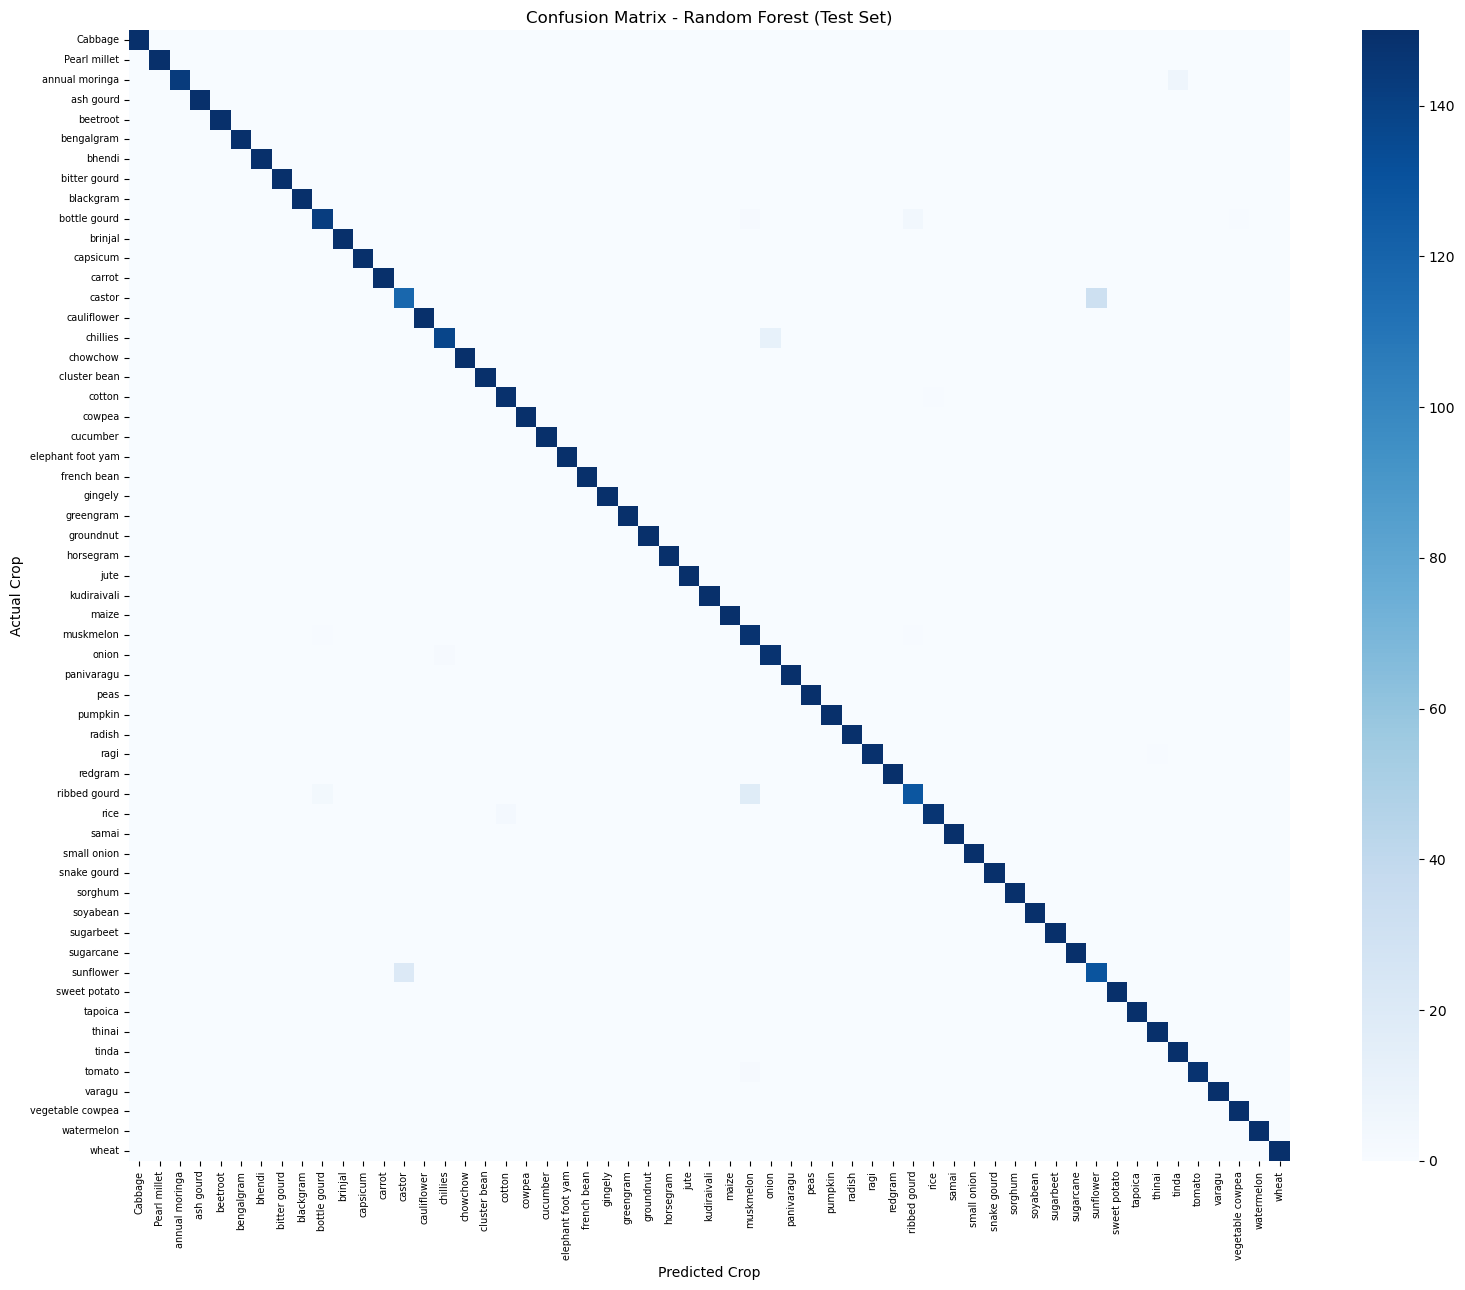

In [42]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get crop labels from the actual and predicted values
crop_labels = sorted(set(y_test) | set(final_prediction))

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    final_prediction,
    labels=crop_labels
)

# Plot confusion matrix
plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=crop_labels,
    yticklabels=crop_labels,
    cbar=True
)

plt.title(f"Confusion Matrix - {best_model_name} (Test Set)")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

TOP 25 FEATURE IMPORTANCES


,Feature,Importance
49,numeric__RELATIVE_HUMIDITY,0.169316
50,numeric__N,0.101987
48,numeric__TEMP,0.093860
52,numeric__K,0.090554
47,numeric__SOIL_PH,0.088690
51,numeric__P,0.056179
24,categorical__SOIL_sandy Loamy soil,0.045083
4,categorical__SOIL_Loamy soil,0.030999
35,categorical__SEASON_kharif,0.022101
36,categorical__SEASON_rabi,0.021234


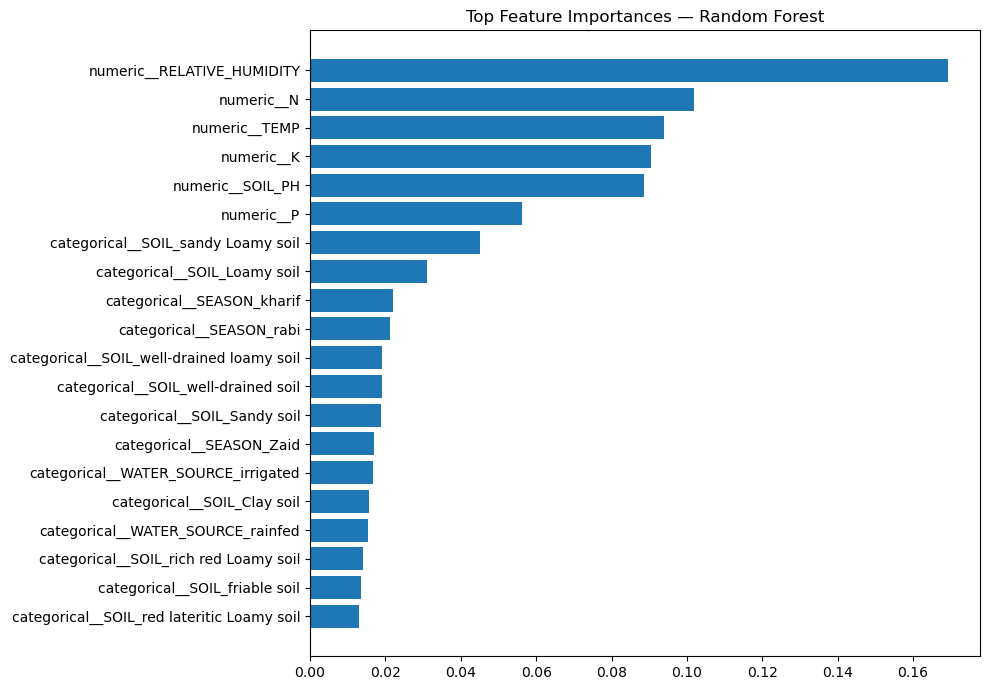

In [43]:
# Feature importance is available for tree-based models. One-hot encoded feature names are shown.
underlying_model = final_model.named_steps["model"]
preprocessor = final_model.named_steps["preprocessor"]
if hasattr(underlying_model, "feature_importances_"):
    transformed_names = preprocessor.get_feature_names_out()
    feature_importance = pd.DataFrame({
        "Feature": transformed_names,
        "Importance": underlying_model.feature_importances_
    }).sort_values("Importance", ascending=False)
    print("TOP 25 FEATURE IMPORTANCES")
    display(feature_importance.head(25))
    plt.figure(figsize=(10, 7))
    top = feature_importance.head(20).sort_values("Importance")
    plt.barh(top["Feature"], top["Importance"])
    plt.title(f"Top Feature Importances — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    feature_importance = pd.DataFrame()
    print(f"{best_model_name} does not provide built-in feature_importances_.")


In [44]:
# Fair final comparison: refit every candidate on train + validation, then evaluate once on test.
test_results = []
final_fitted_models = {}

print("TEST PERFORMANCE OF ALL MODELS")
for name, estimator in models.items():
    print("Evaluating:", name)
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(X_development)),
        ("model", clone(estimator))
    ])
    try:
        pipeline.fit(X_development, y_development)
        pred = pipeline.predict(X_test)
        final_fitted_models[name] = pipeline
        test_results.append({
            "Model": name,
            "Test Accuracy": accuracy_score(y_test, pred),
            "Test Precision (Macro)": precision_score(y_test, pred, average="macro", zero_division=0),
            "Test Recall (Macro)": recall_score(y_test, pred, average="macro", zero_division=0),
            "Test F1 (Macro)": f1_score(y_test, pred, average="macro", zero_division=0)
        })
    except Exception as e:
        print(f"  Model failed: {type(e).__name__}: {e}")

test_df = pd.DataFrame(test_results).sort_values(
    "Test Accuracy", ascending=False
).reset_index(drop=True)
display(test_df.style.format({
    col: "{:.2%}" for col in test_df.columns if col != "Model"
}))


TEST PERFORMANCE OF ALL MODELS
Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: Linear SVM
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Gradient Boosting
Evaluating: AdaBoost
Evaluating: Extra Trees
Evaluating: Gaussian Naive Bayes
  Model failed: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
Evaluating: SGD Classifier
Evaluating: MLP Neural Network
  Model failed: TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''
Evaluating: XGBoost
  Model failed: ValueError: Invalid classes inferred from unique values of `y`.  Expected: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56], got ['Cabbage' 'Pearl millet' 'annual moringa' 'ash gourd' 'beetroot'
 'ben

,Model,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro)
0,Random Forest,98.68%,98.72%,98.68%,98.68%
1,Gradient Boosting,98.62%,98.67%,98.62%,98.62%
2,Decision Tree,97.95%,97.96%,97.95%,97.95%
3,Extra Trees,97.82%,97.88%,97.82%,97.82%
4,Logistic Regression,96.35%,96.36%,96.35%,96.35%
5,KNN,95.26%,95.33%,95.26%,95.22%
6,Linear SVM,94.83%,94.86%,94.83%,94.77%
7,SGD Classifier,92.89%,93.42%,92.89%,92.41%
8,AdaBoost,5.26%,1.47%,5.26%,1.93%


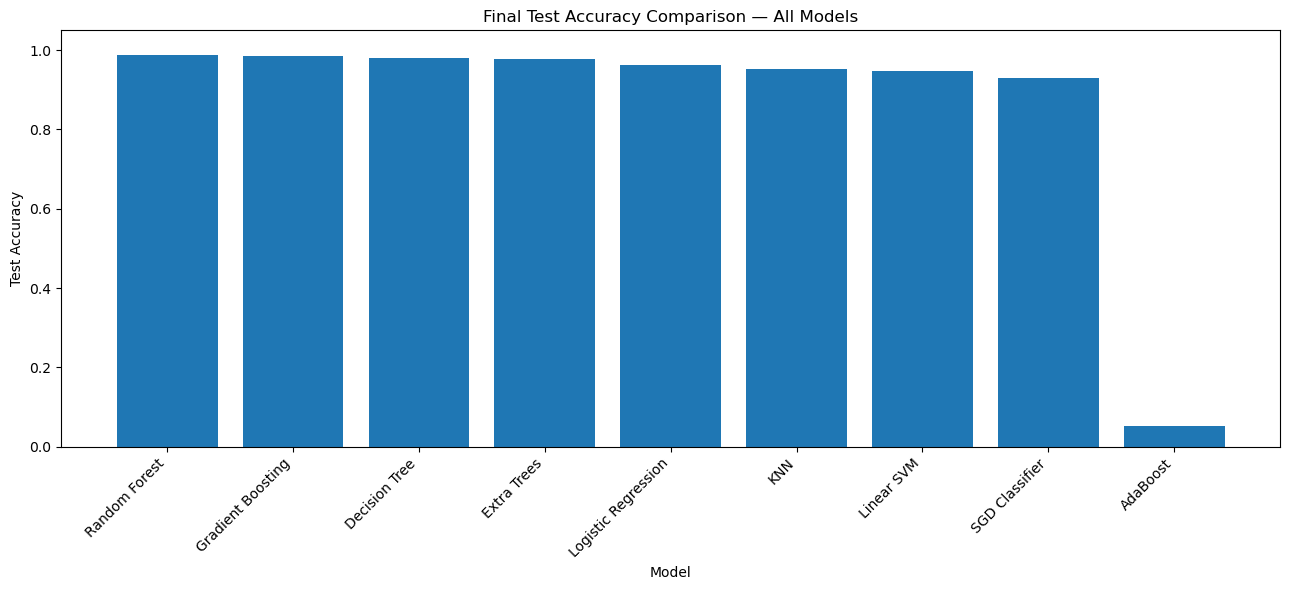

In [45]:
plt.figure(figsize=(13, 6))
plt.bar(test_df["Model"], test_df["Test Accuracy"])
plt.title("Final Test Accuracy Comparison — All Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [46]:
final_results = pd.DataFrame({
    "Metric": ["Selected Model", "Validation Accuracy", "Test Accuracy",
               "Test Macro Precision", "Test Macro Recall", "Test Macro F1"],
    "Value": [best_model_name, f"{best_validation_accuracy:.2%}",
              f"{test_accuracy:.2%}", f"{test_precision:.2%}",
              f"{test_recall:.2%}", f"{test_f1:.2%}"]
})
display(final_results)


,Metric,Value
0,Selected Model,Random Forest
1,Validation Accuracy,98.44%
2,Test Accuracy,98.68%
3,Test Macro Precision,98.72%
4,Test Macro Recall,98.68%
5,Test Macro F1,98.68%


In [47]:
validation_df.to_csv("validation_model_comparison.csv", index=False)
test_df.to_csv("test_model_comparison.csv", index=False)
final_results.to_csv("final_model_results.csv", index=False)
if not feature_importance.empty:
    feature_importance.to_csv("feature_importance.csv", index=False)
print("CSV result files saved to the current notebook folder.")


CSV result files saved to the current notebook folder.


In [48]:
with pd.ExcelWriter("Crop_ML_Benchmark_Results.xlsx", engine="openpyxl") as writer:
    validation_df.to_excel(writer, sheet_name="Validation Results", index=False)
    test_df.to_excel(writer, sheet_name="Test Results", index=False)
    final_results.to_excel(writer, sheet_name="Final Result", index=False)
    if not feature_importance.empty:
        feature_importance.to_excel(writer, sheet_name="Feature Importance", index=False)
print("Excel workbook saved: Crop_ML_Benchmark_Results.xlsx")


Excel workbook saved: Crop_ML_Benchmark_Results.xlsx


In [50]:
print("=" * 70)
print("FINAL PROJECT CONCLUSION")
print("=" * 70)

print(f"Dataset rows used: {len(df):,}")
print(f"Number of input features: {X.shape[1]}")
print(f"Number of crop classes: {y.nunique()}")

print("Split: 70% train / 15% validation / 15% test")
print("Selected using validation data:", best_model_name)

print(f"Validation accuracy: {best_validation_accuracy:.2%}")
print(f"Final test accuracy: {test_accuracy:.2%}")
print(f"Test macro precision: {test_precision:.2%}")
print(f"Test macro recall: {test_recall:.2%}")
print(f"Test macro-F1: {test_f1:.2%}")

print("\nImportant: Verify dataset provenance, measurement units,")
print("and whether samples are synthetic or independently collected.")
print("High random-split accuracy alone does not establish")
print("real-world farm performance.")
print("=" * 70)

FINAL PROJECT CONCLUSION
Dataset rows used: 57,000
Number of input features: 10
Number of crop classes: 57
Split: 70% train / 15% validation / 15% test
Selected using validation data: Random Forest
Validation accuracy: 98.44%
Final test accuracy: 98.68%
Test macro precision: 98.72%
Test macro recall: 98.68%
Test macro-F1: 98.68%

Important: Verify dataset provenance, measurement units,
and whether samples are synthetic or independently collected.
High random-split accuracy alone does not establish
real-world farm performance.
